# 回归模型验证

本notebook用于训练和评估基于湿度数据预测火灾数量的回归模型。

## 1. 导入必要的库和数据准备

In [3]:
import sys
import os
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))

import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')
merged_data, stations = data_processor.prepare_fire_count_data()


合并后的数据信息:
数据形状: (1625, 32)

所有列名:
['datetime', 'LIVERPOOL', 'WYONG', 'NEWCASTLE', 'MAYFIELD', 'TAMWORTH', 'WOLLONGONG', 'ALBURY', 'PARRAMATTA NORTH', 'MUSWELLBROOK', 'SINGLETON', 'MAISON DIEU', 'CAMBERWELL', 'SINGLETON NW', 'MOUNT THORLEY', 'BULGA', 'MUSWELLBROOK NW', 'WYBONG', 'ABERDEEN', 'SINGLETON SOUTH', 'JERRYS PLAINS', 'WARKWORTH', 'MERRIWA', 'CAMDEN', 'MACQUARIE PARK', 'ARMIDALE', 'ORANGE', 'GOULBURN', 'COFFS HARBOUR', 'MORISSET', 'date', 'fire_count']

数据预览:
    datetime  fire_count  LIVERPOOL      WYONG  NEWCASTLE
0 2020-01-19         1.0  83.026087  88.121739  82.252174
1 2020-01-20         1.0  77.865217  83.786957  76.178261
2 2020-01-21         3.0  61.743478  69.852174  60.343478
3 2020-01-22         2.0  61.117391  76.560870  72.408696
4 2020-01-23         9.0  45.543478  48.565217  44.304348



## 2. 数据集划分

In [5]:
from sklearn.model_selection import train_test_split

print("\n正在划分数据集...")
# 准备特征和目标变量
X = merged_data[stations].fillna(merged_data[stations].mean())
y = merged_data['fire_count']  # 这里使用fire_count而不是fire_binary

# 划分训练集、验证集和测试集
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# 数据预处理
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_processed = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_val_processed = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)
X_test_processed = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\n数据集形状:")
print(f"训练集: {X_train_processed.shape}")
print(f"验证集: {X_val_processed.shape}")
print(f"测试集: {X_test_processed.shape}")


正在划分数据集...

数据集形状:
训练集: (1137, 29)
验证集: (244, 29)
测试集: (244, 29)


## 3. 模型训练与评估


Starting model training and evaluation...

Training Linear Regression...
Linear Regression Evaluation Results:
Mean Squared Error (MSE): 62.7596
Root Mean Squared Error (RMSE): 7.9221
R-squared (R²): 0.4932


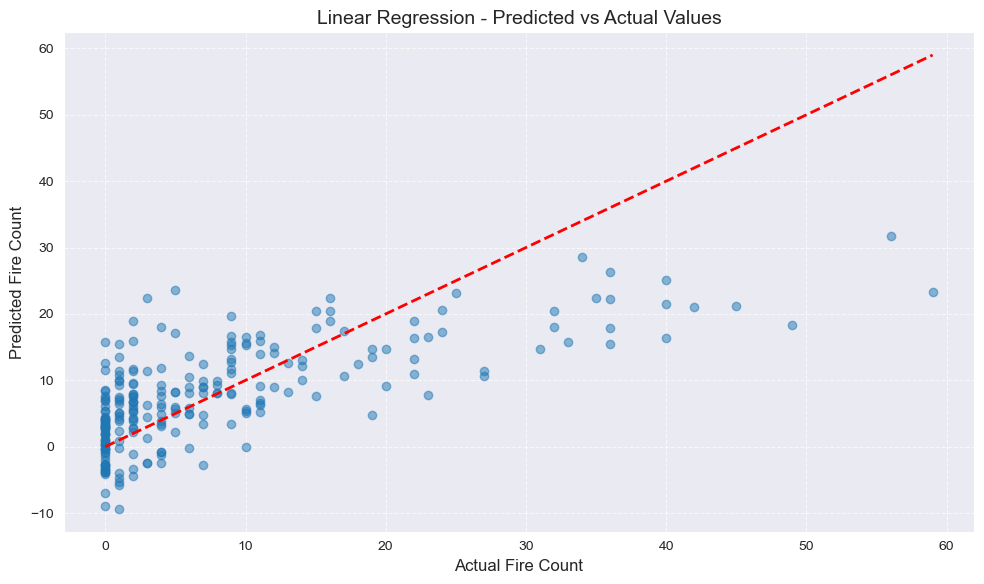

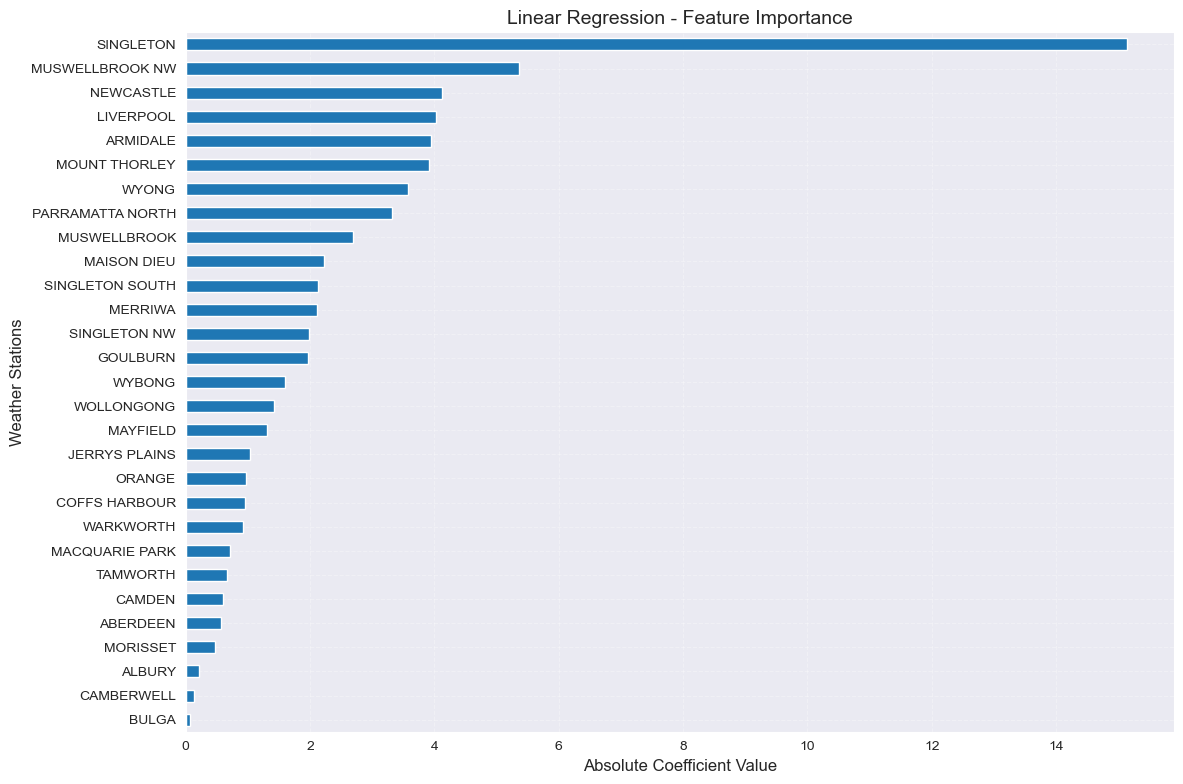


Linear Regression - Top 10 Most Important Features:
MAISON DIEU          2.230880
MUSWELLBROOK         2.688012
PARRAMATTA NORTH     3.317709
WYONG                3.580322
MOUNT THORLEY        3.910581
ARMIDALE             3.945878
LIVERPOOL            4.026111
NEWCASTLE            4.126573
MUSWELLBROOK NW      5.356973
SINGLETON           15.140343
dtype: float64

Training Random Forest...
Random Forest Evaluation Results:
Mean Squared Error (MSE): 68.8598
Root Mean Squared Error (RMSE): 8.2982
R-squared (R²): 0.4439


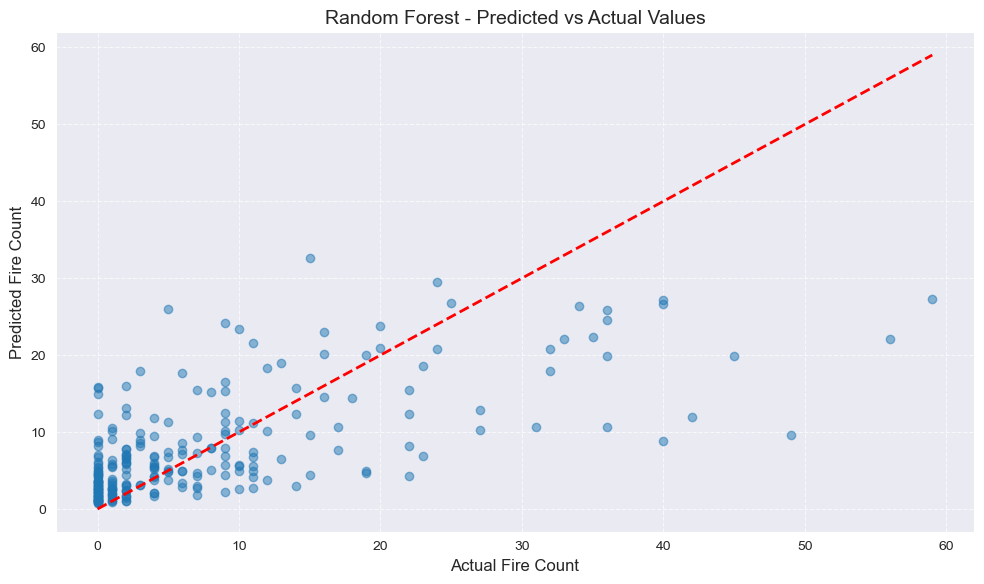

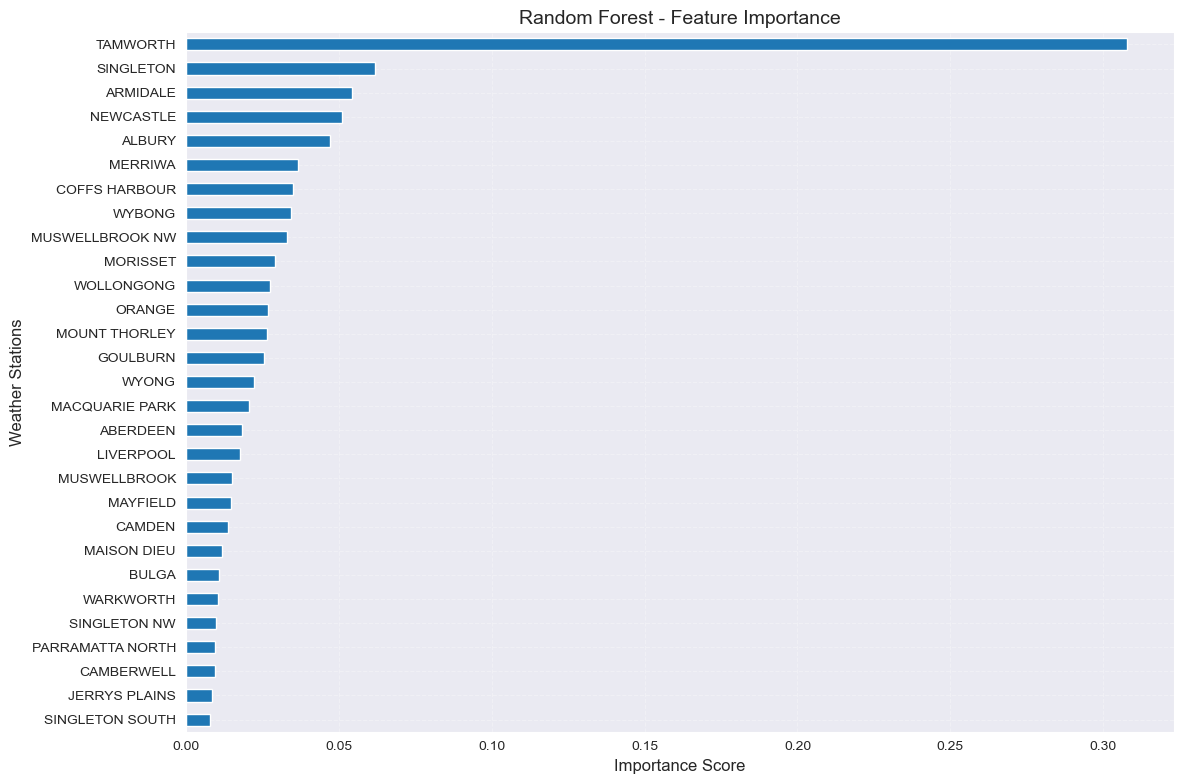


Random Forest - Top 10 Most Important Features:
MORISSET           0.029241
MUSWELLBROOK NW    0.033097
WYBONG             0.034590
COFFS HARBOUR      0.035195
MERRIWA            0.036668
ALBURY             0.047323
NEWCASTLE          0.051226
ARMIDALE           0.054392
SINGLETON          0.061954
TAMWORTH           0.307711
dtype: float64

Model Performance Comparison:
                         MSE      RMSE        R²
Linear Regression  62.759604  7.922096  0.493192
Random Forest      68.859833  8.298183  0.443930


C:\Users\18400\AppData\Local\Temp\ipykernel_46824\80858795.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_46824\80858795.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_46824\80858795.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)


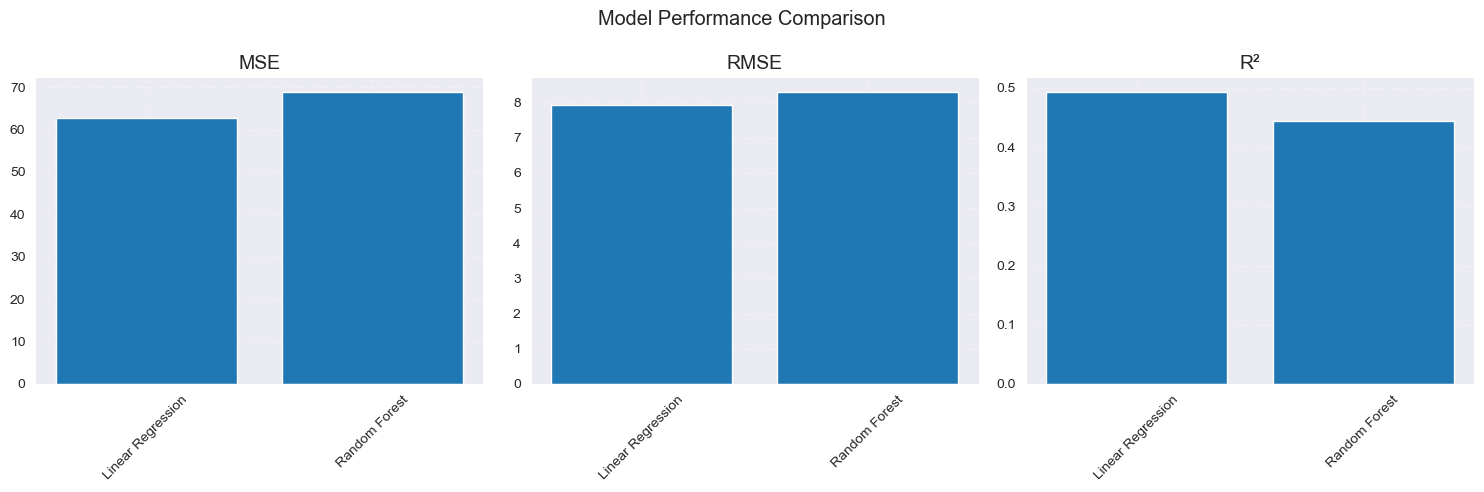

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def train_and_evaluate_models(X_train, X_val, y_train, y_val):
    """
    Train and evaluate regression models
    
    Parameters:
        X_train: Training features
        X_val: Validation features
        y_train: Training target
        y_val: Validation target
        
    Returns:
        Dictionary containing model results
    """
    # Initialize models
    models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(
            n_estimators=100,  
            max_depth=10,      
            random_state=42
        )
    }
    
    results = {}
    
    for name, model in models.items():
        print(f"\nTraining {name}...")
        # Train model
        model.fit(X_train, y_train)
        
        # Predict
        y_pred = model.predict(X_val)
        
        # Calculate metrics
        mse = mean_squared_error(y_val, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_val, y_pred)
        
        # Print evaluation metrics
        print(f"{name} Evaluation Results:")
        print(f"Mean Squared Error (MSE): {mse:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
        print(f"R-squared (R²): {r2:.4f}")
        
        # Scatter plot of predictions vs actual values
        plt.figure(figsize=(10, 6))
        plt.scatter(y_val, y_pred, alpha=0.5)
        plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
        plt.title(f'{name} - Predicted vs Actual Values')
        plt.xlabel('Actual Fire Count')
        plt.ylabel('Predicted Fire Count')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
        
        # Feature importance plots
        if name == 'Random Forest':
            # Random Forest feature importance
            feature_importance = pd.Series(
                model.feature_importances_,
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            feature_importance.plot(kind='barh')
            plt.title('Random Forest - Feature Importance')
            plt.xlabel('Importance Score')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
        
        if name == 'Linear Regression':
            # Linear Regression feature importance (absolute coefficients)
            linear_importance = pd.Series(
                np.abs(model.coef_),
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            linear_importance.plot(kind='barh')
            plt.title('Linear Regression - Feature Importance')
            plt.xlabel('Absolute Coefficient Value')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
            
        # Store results
        results[name] = {
            'model': model,
            'mse': mse,
            'rmse': rmse,
            'r2': r2,
            'predictions': y_pred
        }
        
        # Print feature importance rankings
        if name == 'Random Forest':
            print("\nRandom Forest - Top 10 Most Important Features:")
            print(feature_importance.tail(10))
        
        if name == 'Linear Regression':
            print("\nLinear Regression - Top 10 Most Important Features:")
            print(linear_importance.tail(10))
    
    # Compare model performances
    print("\nModel Performance Comparison:")
    performance_comparison = pd.DataFrame({
        'MSE': [results[model]['mse'] for model in models],
        'RMSE': [results[model]['rmse'] for model in models],
        'R²': [results[model]['r2'] for model in models]
    }, index=models.keys())
    print(performance_comparison)
    
    return results


# Configure plot settings for better readability
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Train and evaluate models
print("\nStarting model training and evaluation...")
model_results = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val)

# Additional visualization: Model performance comparison
metrics = ['MSE', 'RMSE', 'R²']
model_names = list(model_results.keys())
performance_data = []

for metric in metrics:
    if metric == 'MSE':
        values = [results['mse'] for results in model_results.values()]
    elif metric == 'RMSE':
        values = [results['rmse'] for results in model_results.values()]
    else:  # R²
        values = [results['r2'] for results in model_results.values()]
    performance_data.append(values)

# Plot model performance comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance Comparison')

for i, (metric, ax) in enumerate(zip(metrics, axes)):
    ax.bar(model_names, performance_data[i])
    ax.set_title(metric)
    ax.set_xticklabels(model_names, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()